# K-Nearest Neighbors (KNN) Classification

## Project Objective

The objective of this project is to build a K-Nearest Neighbors (KNN)
classification model using the breast cancer dataset and evaluate its
performance on unseen data.

In [8]:
import numpy as np
import pandas as pd

##  Loading the Dataset

In this section, we load the breast cancer dataset using Pandas.
The dataset will be used to train and evaluate our K-Nearest Neighbors
(KNN) classification model.

In [9]:
df = pd.read_csv('breast-cancer.csv')

##  Exploring the Dataset

First, we inspect the dataset to understand its structure, features,
data types, and whether there are any missing values.

In [10]:
df.head(5)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [11]:
df.shape

(569, 32)

In [32]:
df.sample()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
527,B,12.34,12.27,78.94,468.5,0.09003,0.06307,0.02958,0.02647,0.1689,...,13.61,19.27,87.22,564.9,0.1292,0.2074,0.1791,0.107,0.311,0.07592


##  Train-Test Split

We divide the dataset into training and testing sets. The training data
is used to train the model, while the testing data is used to evaluate
how well the model performs on unseen data.

In [33]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df.iloc[:,1:],df.iloc[:,0],test_size=0.2,random_state=2)

In [36]:
y_train.shape

(455,)

## Feature Scaling

KNN is a distance-based algorithm, so features with larger numerical
ranges can have a greater influence on the distance calculation.

To ensure that all features contribute more comparably, we use
StandardScaler to standardize the features.

In [38]:
from sklearn.preprocessing import StandardScaler

In [39]:
scaler = StandardScaler()

In [44]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [45]:
X_train

array([[-0.01330339,  1.7757658 , -0.01491962, ..., -0.13236958,
        -1.08014517, -0.03527943],
       [-0.8448276 , -0.6284278 , -0.87702746, ..., -1.11552632,
        -0.85773964, -0.72098905],
       [ 1.44755936,  0.71180168,  1.47428816, ...,  0.87583964,
         0.4967602 ,  0.46321706],
       ...,
       [-0.46608541, -1.49375484, -0.53234924, ..., -1.32388956,
        -1.02997851, -0.75145272],
       [-0.50025764, -1.62161319, -0.527814  , ..., -0.0987626 ,
         0.35796577, -0.43906159],
       [ 0.96060511,  1.21181916,  1.00427242, ...,  0.8956983 ,
        -1.23064515,  0.50697397]], shape=(455, 30))

In [46]:
X_test

array([[-0.08700339, -1.47192915, -0.10537391, ..., -0.26629174,
        -1.09776353, -0.65597459],
       [ 0.19989092,  0.03577342,  0.1706179 , ...,  0.44844054,
         0.06066588,  0.02108157],
       [-1.28858427, -0.21847659, -1.30667757, ..., -1.41981535,
         0.19788632, -0.31050377],
       ...,
       [ 0.67523542,  0.61546345,  0.70329853, ...,  1.36221218,
         1.000987  ,  0.62759948],
       [ 0.20832899,  1.5866985 ,  0.10942329, ..., -1.35965118,
        -1.95719681, -1.62740299],
       [ 0.78774299,  0.03068842,  0.84293725, ...,  2.03773974,
         0.27299646,  0.34822356]], shape=(114, 30))

##  K-Nearest Neighbors Model

K-Nearest Neighbors (KNN) is a supervised machine learning algorithm
used for classification. The model predicts the class of a new data
point based on the classes of its nearest neighbors.

In [79]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=11)

In [80]:
knn.fit(X_train,y_train)

,n_neighbors,11
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


##  Model Evaluation

After training the KNN model, we evaluate its performance on the test
data using appropriate evaluation metrics.

In [81]:
from sklearn.metrics import accuracy_score
y_pred = knn.predict(X_test)
accuracy_score(y_test,y_pred)

0.9736842105263158

In [82]:
scores = []
for i in range(1,16):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train,y_train)
    y_pred = knn.predict(X_test)
    scores.append(accuracy_score(y_test,y_pred))

In [76]:
scores

[0.956140350877193,
 0.9736842105263158,
 0.9736842105263158,
 0.9736842105263158,
 0.9736842105263158,
 0.9736842105263158,
 0.9736842105263158,
 0.9736842105263158,
 0.9736842105263158,
 0.9649122807017544,
 0.9736842105263158,
 0.956140350877193,
 0.9649122807017544,
 0.9649122807017544,
 0.9649122807017544]

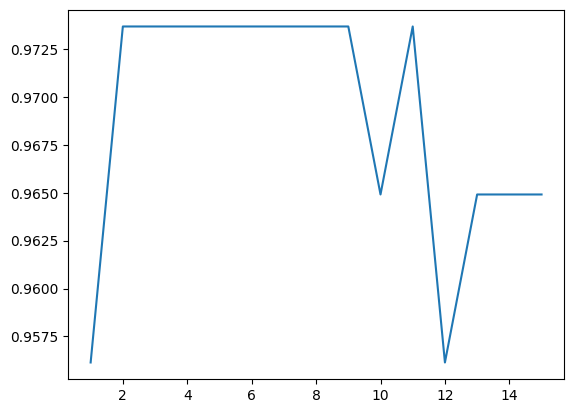

In [78]:
import matplotlib.pyplot as plt
plt.plot(range(1,16),scores)

##  Conclusion

The KNN model was trained and evaluated on the dataset. The results
provide an indication of how well the model can classify previously
unseen observations.